In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from datetime import datetime

In [ ]:
df = pd.read_csv('katalog_gempa.csv')

print("Shape dataset:", df.shape)
print("\nKolom:", df.columns.tolist())
print("\nPreview data:")
df.head()

Shape dataset: (92887, 13)

Kolom: ['tgl', 'ot', 'lat', 'lon', 'depth', 'mag', 'remark', 'strike1', 'dip1', 'rake1', 'strike2', 'dip2', 'rake2']

Preview data:


,tgl,ot,lat,lon,depth,mag,remark,strike1,dip1,rake1,strike2,dip2,rake2
0,2008/11/01,21:02:43.058,-9.18,119.06,10,4.9,Sumba Region - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
1,2008/11/01,20:58:50.248,-6.55,129.64,10,4.6,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN
2,2008/11/01,17:43:12.941,-7.01,106.63,121,3.7,Java - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
3,2008/11/01,16:24:14.755,-3.30,127.85,10,3.2,Seram - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
4,2008/11/01,16:20:37.327,-6.41,129.54,70,4.3,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.tail()

,tgl,ot,lat,lon,depth,mag,remark,strike1,dip1,rake1,strike2,dip2,rake2
92882,2023/01/26,02:25:09.288,3.24,127.18,10,4.0,Talaud Islands - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN
92883,2023/01/26,02:15:03.893,2.70,127.10,10,3.9,Northern Molucca Sea,NaN,NaN,NaN,NaN,NaN,NaN
92884,2023/01/26,01:57:08.885,-7.83,121.07,10,3.8,Flores Sea,NaN,NaN,NaN,NaN,NaN,NaN
92885,2023/01/26,01:46:21.009,3.00,127.16,10,4.1,Northern Molucca Sea,NaN,NaN,NaN,NaN,NaN,NaN
92886,2023/01/26,00:00:35.181,-8.87,118.95,10,2.4,Sumbawa Region - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN


Exploratory Data Analysis (EDA)

In [ ]:
print(df.info())

print(df.isnull().sum())

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92887 entries, 0 to 92886
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   tgl      92887 non-null  object 
 1   ot       92887 non-null  object 
 2   lat      92887 non-null  float64
 3   lon      92887 non-null  float64
 4   depth    92887 non-null  int64  
 5   mag      92887 non-null  float64
 6   remark   92887 non-null  object 
 7   strike1  2735 non-null   float64
 8   dip1     2735 non-null   float64
 9   rake1    2735 non-null   float64
 10  strike2  2735 non-null   float64
 11  dip2     2735 non-null   float64
 12  rake2    2735 non-null   float64
dtypes: float64(9), int64(1), object(3)
memory usage: 9.2+ MB
None
tgl            0
ot             0
lat            0
lon            0
depth          0
mag            0
remark         0
strike1    90152
dip1       90152
rake1      90152
strike2    90152
dip2       90152
rake2      90152
dtype: int64
                lat 

SOAL 1: Identifikasi & Cleaning Kolom Remark

In [ ]:
# kolom remark (soalnya format gk sama)
print("SEBELUM CLEANING")
print(df['remark'].value_counts().head(20))
print("\nContoh nilai unik remark:")
print(df['remark'].unique()[:30])

SEBELUM CLEANING
remark
Minahassa Peninsula - Sulawesi    9433
Sulawesi - Indonesia              7897
Sumbawa Region - Indonesia        7312
Java - Indonesia                  6798
Northern Sumatra - Indonesia      5941
Southern Sumatra - Indonesia      5314
Banda Sea                         5003
Northern Molucca Sea              4984
Seram - Indonesia                 4325
Halmahera - Indonesia             3628
Irian Jaya Region - Indonesia     3137
South of Java - Indonesia         2503
Talaud Islands - Indonesia        2427
Flores Region - Indonesia         2338
Timor Region                      1947
Flores Sea                        1879
Near North Coast of Irian Jaya    1865
Sumba Region - Indonesia          1851
Irian Jaya - Indonesia            1666
Ceram Sea                         1535
Name: count, dtype: int64

Contoh nilai unik remark:
['Sumba Region - Indonesia' 'Banda Sea' 'Java - Indonesia'
 'Seram - Indonesia' 'Northern Sumatra - Indonesia'
 'Southern Sumatra - Indonesia' 

Pipeline Cleaning

In [ ]:
def clean_text_pipeline(text):
    if pd.isnull(text):
        return text
    text = text.lower()
    text = text.strip()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^a-z0-9\s\-]', '', text)
    text = re.sub(r'\s*-\s*', ' - ', text)
    return text

df['remark_clean'] = df['remark'].apply(clean_text_pipeline)

print("SETELAH CLEANING")
print(df['remark_clean'].value_counts().head(20))

print("\nPerbandingan sebelum vs sesudah:")
print(df[['remark', 'remark_clean']].head(10))

SETELAH CLEANING
remark_clean
minahassa peninsula - sulawesi    9433
sulawesi - indonesia              7897
sumbawa region - indonesia        7312
java - indonesia                  6798
northern sumatra - indonesia      5941
southern sumatra - indonesia      5314
banda sea                         5003
northern molucca sea              4984
seram - indonesia                 4325
halmahera - indonesia             3628
irian jaya region - indonesia     3137
south of java - indonesia         2503
talaud islands - indonesia        2427
flores region - indonesia         2338
timor region                      1947
flores sea                        1879
near north coast of irian jaya    1865
sumba region - indonesia          1851
irian jaya - indonesia            1666
ceram sea                         1535
Name: count, dtype: int64

Perbandingan sebelum vs sesudah:
                         remark                  remark_clean
0      Sumba Region - Indonesia      sumba region - indonesia
1     

In [ ]:
df

,tgl,ot,lat,lon,depth,mag,remark,strike1,dip1,rake1,strike2,dip2,rake2,remark_clean
0,2008/11/01,21:02:43.058,-9.18,119.06,10,4.9,Sumba Region - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN,sumba region - indonesia
1,2008/11/01,20:58:50.248,-6.55,129.64,10,4.6,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN,banda sea
2,2008/11/01,17:43:12.941,-7.01,106.63,121,3.7,Java - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN,java - indonesia
3,2008/11/01,16:24:14.755,-3.30,127.85,10,3.2,Seram - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN,seram - indonesia
4,2008/11/01,16:20:37.327,-6.41,129.54,70,4.3,Banda Sea,NaN,NaN,NaN,NaN,NaN,NaN,banda sea
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92882,2023/01/26,02:25:09.288,3.24,127.18,10,4.0,Talaud Islands - Indonesia,NaN,NaN,NaN,NaN,NaN,NaN,talaud islands - indonesia
92883,2023/01/26,02:15:03.893,2.70,127.10,10,3.9,Northern Molucca Sea,NaN,NaN,NaN,NaN,NaN,NaN,northern molucca sea
92884,2023/01/26,01:57:08.885,-7.83,121.07,10,3.8,Flores Sea,NaN,NaN,NaN,NaN,NaN,NaN,flores sea
92885,2023/01/26,01:46:21.009,3.00,127.16,10,4.1,Northern Molucca Sea,NaN,NaN,NaN,NaN,NaN,NaN,northern molucca sea


SOAL 2: Feature Engineering dari Kolom Tanggal

In [ ]:
df['tgl'] = pd.to_datetime(df['tgl'], format='%Y/%m/%d')

df['tahun']  = df['tgl'].dt.year
df['bulan']  = df['tgl'].dt.month
df['hari']   = df['tgl'].dt.day
df['hari_dalam_minggu'] = df['tgl'].dt.day_name()

df['jam'] = df['ot'].apply(lambda x: int(str(x).split(':')[0]))

def kategori_waktu(jam):
    if 5 <= jam < 12:
        return 'Pagi'
    elif 12 <= jam < 17:
        return 'Siang'
    elif 17 <= jam < 21:
        return 'Sore'
    else:
        return 'Malam'

df['kategori_waktu'] = df['jam'].apply(kategori_waktu)

# kedalaman gempa
def kategori_kedalaman(depth):
    if depth <= 60:
        return 'Dangkal'
    elif depth <= 300:
        return 'Menengah'
    else:
        return 'Dalam'

df['kategori_kedalaman'] = df['depth'].apply(kategori_kedalaman)

# magnitudo
def kategori_magnitudo(mag):
    if mag < 3.0:
        return 'Mikro'
    elif mag < 5.0:
        return 'Kecil'
    elif mag < 7.0:
        return 'Sedang'
    else:
        return 'Besar'

df['kategori_mag'] = df['mag'].apply(kategori_magnitudo)

print("Kolom baru hasil feature engineering:")
print(df[['tgl', 'tahun', 'bulan', 'hari', 'hari_dalam_minggu', 'jam', 'kategori_waktu', 'kategori_kedalaman', 'kategori_mag']].head(10))

Kolom baru hasil feature engineering:
         tgl  tahun  bulan  hari hari_dalam_minggu  jam kategori_waktu  \
0 2008-11-01   2008     11     1          Saturday   21          Malam   
1 2008-11-01   2008     11     1          Saturday   20           Sore   
2 2008-11-01   2008     11     1          Saturday   17           Sore   
3 2008-11-01   2008     11     1          Saturday   16          Siang   
4 2008-11-01   2008     11     1          Saturday   16          Siang   
5 2008-11-01   2008     11     1          Saturday   14          Siang   
6 2008-11-01   2008     11     1          Saturday   13          Siang   
7 2008-11-01   2008     11     1          Saturday   10           Pagi   
8 2008-11-01   2008     11     1          Saturday    9           Pagi   
9 2008-11-01   2008     11     1          Saturday    6           Pagi   

  kategori_kedalaman kategori_mag  
0            Dangkal        Kecil  
1            Dangkal        Kecil  
2           Menengah        Kecil  
3  

In [ ]:
df

,tgl,ot,lat,lon,depth,mag,remark,strike1,dip1,rake1,...,rake2,remark_clean,tahun,bulan,hari,hari_dalam_minggu,jam,kategori_waktu,kategori_kedalaman,kategori_mag
0,2008-11-01,21:02:43.058,-9.18,119.06,10,4.9,Sumba Region - Indonesia,NaN,NaN,NaN,...,NaN,sumba region - indonesia,2008,11,1,Saturday,21,Malam,Dangkal,Kecil
1,2008-11-01,20:58:50.248,-6.55,129.64,10,4.6,Banda Sea,NaN,NaN,NaN,...,NaN,banda sea,2008,11,1,Saturday,20,Sore,Dangkal,Kecil
2,2008-11-01,17:43:12.941,-7.01,106.63,121,3.7,Java - Indonesia,NaN,NaN,NaN,...,NaN,java - indonesia,2008,11,1,Saturday,17,Sore,Menengah,Kecil
3,2008-11-01,16:24:14.755,-3.30,127.85,10,3.2,Seram - Indonesia,NaN,NaN,NaN,...,NaN,seram - indonesia,2008,11,1,Saturday,16,Siang,Dangkal,Kecil
4,2008-11-01,16:20:37.327,-6.41,129.54,70,4.3,Banda Sea,NaN,NaN,NaN,...,NaN,banda sea,2008,11,1,Saturday,16,Siang,Menengah,Kecil
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92882,2023-01-26,02:25:09.288,3.24,127.18,10,4.0,Talaud Islands - Indonesia,NaN,NaN,NaN,...,NaN,talaud islands - indonesia,2023,1,26,Thursday,2,Malam,Dangkal,Kecil
92883,2023-01-26,02:15:03.893,2.70,127.10,10,3.9,Northern Molucca Sea,NaN,NaN,NaN,...,NaN,northern molucca sea,2023,1,26,Thursday,2,Malam,Dangkal,Kecil
92884,2023-01-26,01:57:08.885,-7.83,121.07,10,3.8,Flores Sea,NaN,NaN,NaN,...,NaN,flores sea,2023,1,26,Thursday,1,Malam,Dangkal,Kecil
92885,2023-01-26,01:46:21.009,3.00,127.16,10,4.1,Northern Molucca Sea,NaN,NaN,NaN,...,NaN,northern molucca sea,2023,1,26,Thursday,1,Malam,Dangkal,Kecil


Drop kolom2 yg tidak perlu

In [ ]:
df = df.drop(['ot','strike1', 'dip1', 'rake1', 'strike2', 'dip2', 'rake2'], axis=1)

In [ ]:
df

,tgl,lat,lon,depth,mag,remark,remark_clean,tahun,bulan,hari,hari_dalam_minggu,jam,kategori_waktu,kategori_kedalaman,kategori_mag
0,2008-11-01,-9.18,119.06,10,4.9,Sumba Region - Indonesia,sumba region - indonesia,2008,11,1,Saturday,21,Malam,Dangkal,Kecil
1,2008-11-01,-6.55,129.64,10,4.6,Banda Sea,banda sea,2008,11,1,Saturday,20,Sore,Dangkal,Kecil
2,2008-11-01,-7.01,106.63,121,3.7,Java - Indonesia,java - indonesia,2008,11,1,Saturday,17,Sore,Menengah,Kecil
3,2008-11-01,-3.30,127.85,10,3.2,Seram - Indonesia,seram - indonesia,2008,11,1,Saturday,16,Siang,Dangkal,Kecil
4,2008-11-01,-6.41,129.54,70,4.3,Banda Sea,banda sea,2008,11,1,Saturday,16,Siang,Menengah,Kecil
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92882,2023-01-26,3.24,127.18,10,4.0,Talaud Islands - Indonesia,talaud islands - indonesia,2023,1,26,Thursday,2,Malam,Dangkal,Kecil
92883,2023-01-26,2.70,127.10,10,3.9,Northern Molucca Sea,northern molucca sea,2023,1,26,Thursday,2,Malam,Dangkal,Kecil
92884,2023-01-26,-7.83,121.07,10,3.8,Flores Sea,flores sea,2023,1,26,Thursday,1,Malam,Dangkal,Kecil
92885,2023-01-26,3.00,127.16,10,4.1,Northern Molucca Sea,northern molucca sea,2023,1,26,Thursday,1,Malam,Dangkal,Kecil


Visualisasi Pola Data

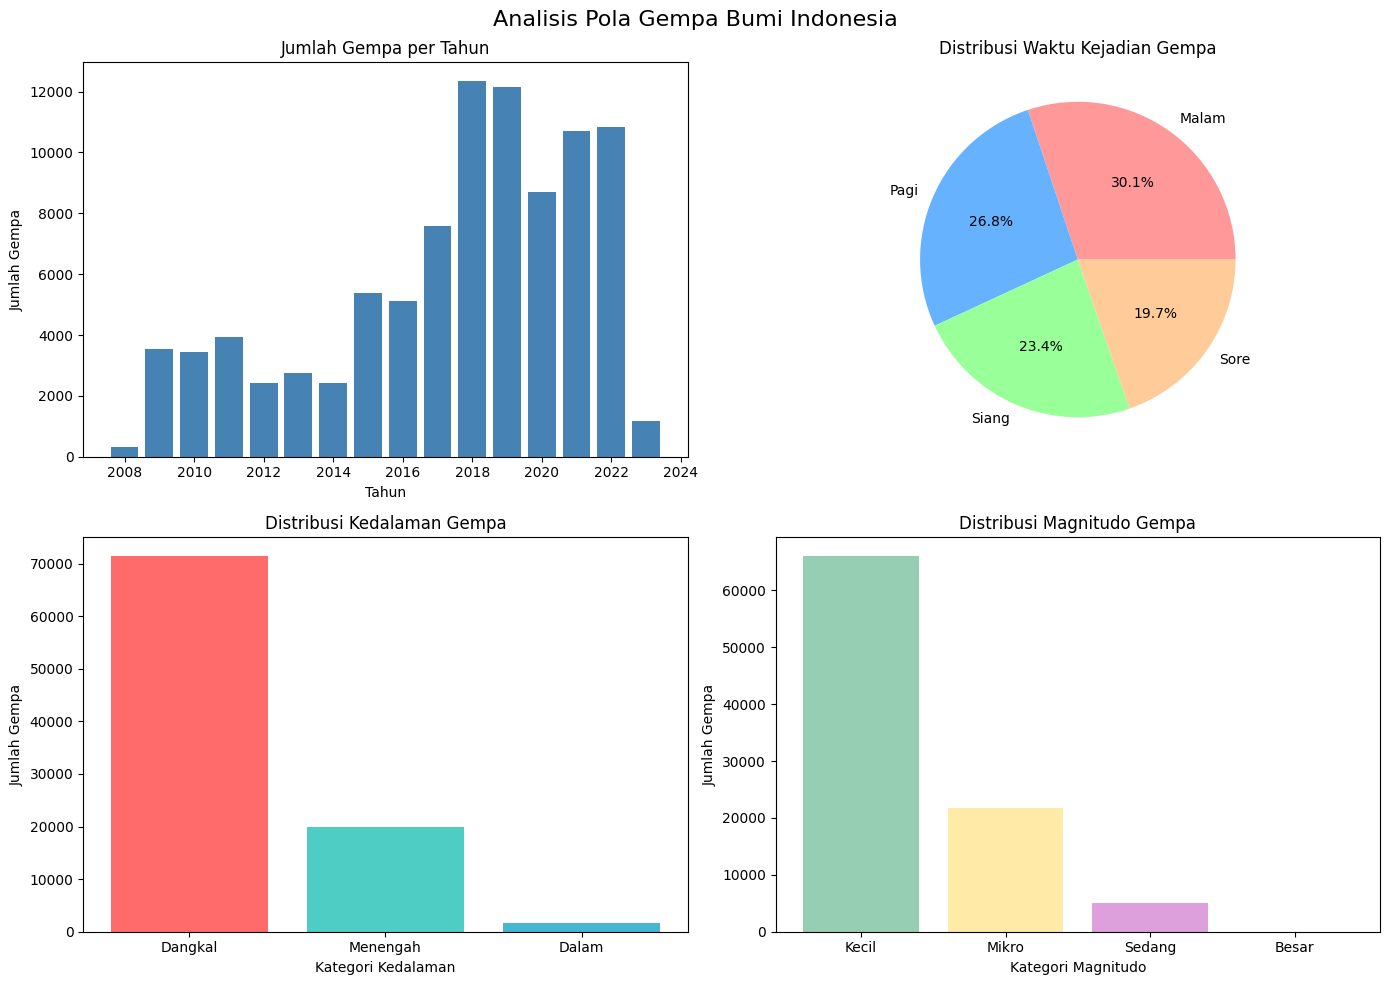

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Analisis Pola Gempa Bumi Indonesia', fontsize=16)

gempa_per_tahun = df['tahun'].value_counts().sort_index()
axes[0,0].bar(gempa_per_tahun.index, gempa_per_tahun.values, color='steelblue')
axes[0,0].set_title('Jumlah Gempa per Tahun')
axes[0,0].set_xlabel('Tahun')
axes[0,0].set_ylabel('Jumlah Gempa')

waktu_counts = df['kategori_waktu'].value_counts()
axes[0,1].pie(waktu_counts.values, labels=waktu_counts.index, autopct='%1.1f%%', colors=['#FF9999','#66B2FF','#99FF99','#FFCC99'])
axes[0,1].set_title('Distribusi Waktu Kejadian Gempa')

kedalaman_counts = df['kategori_kedalaman'].value_counts()
axes[1,0].bar(kedalaman_counts.index, kedalaman_counts.values, color=['#FF6B6B','#4ECDC4','#45B7D1'])
axes[1,0].set_title('Distribusi Kedalaman Gempa')
axes[1,0].set_xlabel('Kategori Kedalaman')
axes[1,0].set_ylabel('Jumlah Gempa')

mag_counts = df['kategori_mag'].value_counts()
axes[1,1].bar(mag_counts.index, mag_counts.values, color=['#96CEB4','#FFEAA7','#DDA0DD','#F08080'])
axes[1,1].set_title('Distribusi Magnitudo Gempa')
axes[1,1].set_xlabel('Kategori Magnitudo')
axes[1,1].set_ylabel('Jumlah Gempa')

plt.tight_layout()
plt.show()

SOAL 3: Ringkasan Data Final

In [ ]:
kolom_final = ['tahun', 'bulan', 'hari', 'hari_dalam_minggu',
               'jam', 'kategori_waktu', 'lat', 'lon', 'depth',
               'kategori_kedalaman', 'mag', 'kategori_mag', 'remark_clean']

df_final = df[kolom_final].copy()

print("RINGKASAN DATA FINAL")
print(f"Total baris  : {len(df_final)}")
print(f"Total kolom  : {len(df_final.columns)}")
print(f"\nDaftar kolom : {df_final.columns.tolist()}")
print(df_final.isnull().sum())
print(df_final.describe())
df_final.head(10)

RINGKASAN DATA FINAL
Total baris  : 92887
Total kolom  : 13

Daftar kolom : ['tahun', 'bulan', 'hari', 'hari_dalam_minggu', 'jam', 'kategori_waktu', 'lat', 'lon', 'depth', 'kategori_kedalaman', 'mag', 'kategori_mag', 'remark_clean']
tahun                 0
bulan                 0
hari                  0
hari_dalam_minggu     0
jam                   0
kategori_waktu        0
lat                   0
lon                   0
depth                 0
kategori_kedalaman    0
mag                   0
kategori_mag          0
remark_clean          0
dtype: int64
              tahun         bulan          hari           jam           lat  \
count  92887.000000  92887.000000  92887.000000  92887.000000  92887.000000   
mean    2017.448588      6.546998     15.671752     12.031318     -3.404577   
std        3.771394      3.564706      8.793203      6.734225      4.354584   
min     2008.000000      1.000000      1.000000      0.000000    -11.000000   
25%     2015.000000      3.000000      8.000000

,tahun,bulan,hari,hari_dalam_minggu,jam,kategori_waktu,lat,lon,depth,kategori_kedalaman,mag,kategori_mag,remark_clean
0,2008,11,1,Saturday,21,Malam,-9.18,119.06,10,Dangkal,4.9,Kecil,sumba region - indonesia
1,2008,11,1,Saturday,20,Sore,-6.55,129.64,10,Dangkal,4.6,Kecil,banda sea
2,2008,11,1,Saturday,17,Sore,-7.01,106.63,121,Menengah,3.7,Kecil,java - indonesia
3,2008,11,1,Saturday,16,Siang,-3.30,127.85,10,Dangkal,3.2,Kecil,seram - indonesia
4,2008,11,1,Saturday,16,Siang,-6.41,129.54,70,Menengah,4.3,Kecil,banda sea
5,2008,11,1,Saturday,14,Siang,-7.37,105.31,18,Dangkal,3.3,Kecil,java - indonesia
6,2008,11,1,Saturday,13,Siang,0.10,98.55,12,Dangkal,4.7,Kecil,northern sumatra - indonesia
7,2008,11,1,Saturday,10,Pagi,-7.07,129.67,135,Menengah,4.8,Kecil,banda sea
8,2008,11,1,Saturday,9,Pagi,-3.32,128.02,10,Dangkal,2.3,Mikro,seram - indonesia
9,2008,11,1,Saturday,6,Pagi,-4.43,127.45,10,Dangkal,3.2,Kecil,banda sea


Export ke Excel

In [ ]:
!pip install openpyxl

output_filename = 'Najwa_Nadhira_Ramadhani_202432033_Laporan2_PBD_A.xlsx'
df_final.to_excel(output_filename, index=False, engine='openpyxl')
print(f"Data berhasil diekspor ke: {output_filename}")

Data berhasil diekspor ke: Najwa_Nadhira_Ramadhani_202432033_Laporan2_PBD_A.xlsx
